<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo" />
</center>

# 3.2. Python Analysis & Visualization

**Dữ liệu:** `data/processed/olist_analysis_dataset.csv` - bảng phân tích gồm `order_id`, `delay_days`, `item_count`, `review_score`, `low_review`.

Mục tiêu: dùng biểu đồ kiểm tra mối liên hệ giữa độ trễ giao hàng, số lượng sản phẩm trong đơn với điểm đánh giá của khách hàng, làm cơ sở cho phần Feature Selection Insights.

### Data Preparation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").is_dir())
df = pd.read_csv(BASE_DIR / "data" / "processed" / "olist_analysis_dataset.csv")

print(df.shape)
df.head()

(95824, 5)


,order_id,delay_days,item_count,review_score,low_review
0,e481f51cbdc54678b7cc49136f2d6af7,-8,1,4,0
1,53cdb2fc8bc7dce0b6741e2150273451,-6,1,4,0
2,47770eb9100c2d0c44946d9cf07ec65d,-18,1,5,0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,1,5,0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,1,5,0


In [3]:
print(df.dtypes)
print(df.isnull().sum())

order_id          str
delay_days      int64
item_count      int64
review_score    int64
low_review      int64
dtype: object
order_id        0
delay_days      0
item_count      0
review_score    0
low_review      0
dtype: int64


In [4]:
# Loại dòng thiếu dữ liệu ở các biến dùng để phân tích (dữ liệu hiện tại không có giá trị thiếu)
df = df.dropna(subset=["delay_days", "item_count", "review_score", "low_review"])
print("Số dòng sau khi kiểm tra:", len(df))

Số dòng sau khi kiểm tra: 95824


## 3.2.1. Delivery Delay vs Review Score

**Research Question:** Do orders with lower review scores tend to experience longer delivery delays?

Biểu đồ box plot so sánh phân phối `delay_days` theo từng mức `review_score` (1-5). Đường đỏ nét đứt là mốc `delay_days = 0` (giao đúng hạn).

              median   mean
review_score               
1               -7.0  -4.04
2              -10.0  -8.66
3              -11.0 -10.77
4              -12.0 -12.38
5              -13.0 -13.38


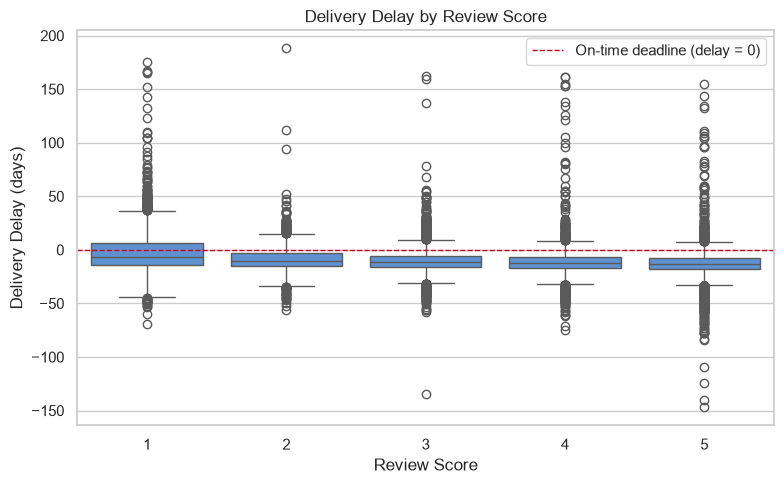

In [5]:
print(df.groupby("review_score")["delay_days"].agg(["median", "mean"]).round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="review_score", y="delay_days", color="#4A90E2")
plt.axhline(0, color="#D0021B", linestyle="--", linewidth=1, label="On-time deadline (delay = 0)")

plt.title("Delivery Delay by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Delivery Delay (days)")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** trung vị `delay_days` tăng từ -7 ngày (score 1) lên -13 ngày (score 5), trung bình tăng từ -4,04 lên -13,38 ngày. Đa số đơn đều đến sớm hơn dự kiến (trung vị âm), nhưng nhóm điểm càng thấp thì thời gian giao càng sát hạn hoặc trễ hơn khoảng 6 ngày so với nhóm điểm 5.

## 3.2.2. Delivery Status vs Low Review Rate

**Research Question:** Do late deliveries have a higher low-review rate than on-time or early deliveries?

Chia đơn thành hai nhóm: **Late** (`delay_days > 0`) và **On time / Early** (`delay_days <= 0`), sau đó tính `low_review_rate = mean(low_review) * 100`.

                 count  mean  low_review_rate
delivery_status                              
Late              6381  0.62            62.37
On time / Early  89443  0.09             9.27


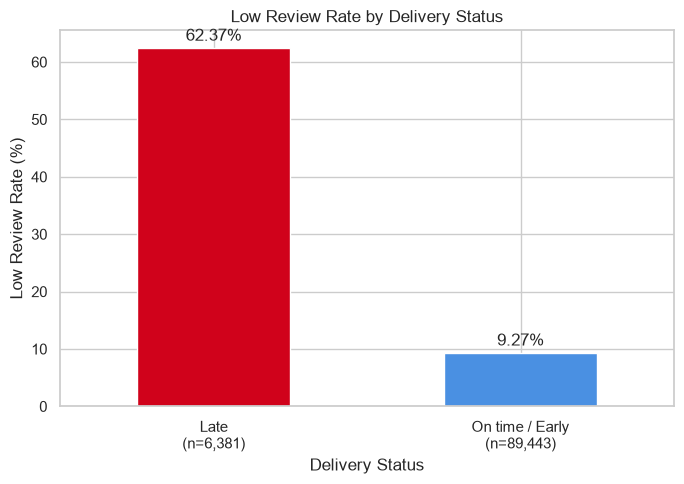

In [6]:
df["delivery_status"] = np.where(df["delay_days"] > 0, "Late", "On time / Early")

summary = df.groupby("delivery_status")["low_review"].agg(["count", "mean"])
summary["low_review_rate"] = summary["mean"] * 100
print(summary.round(2))

ax = summary["low_review_rate"].plot(kind="bar", figsize=(7, 5), color=["#D0021B", "#4A90E2"])
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set_xticklabels([f"{name}\n(n={int(row['count']):,})" for name, row in summary.iterrows()], rotation=0)

plt.title("Low Review Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Low Review Rate (%)")
plt.tight_layout()
plt.show()

**Nhận xét:** đơn giao trễ có tỷ lệ đánh giá thấp 62,37% (3.980/6.381 đơn), cao hơn 53,10 điểm phần trăm so với đơn đúng hạn hoặc sớm (9,27%, tương ứng 8.288/89.443 đơn). Đơn trễ chỉ chiếm 6,66% tổng số đơn nhưng đóng góp 3.980/12.268 đánh giá thấp, tức khoảng 32,4%.

## 3.2.3. Item Count vs Low Review Rate

**Research Question:** Is the number of items in an order associated with the probability of receiving a low review?

Gộp `item_count` thành ba nhóm: 1 sản phẩm, 2-3 sản phẩm và từ 4 sản phẩm trở lên.

            count  mean  low_review_rate
item_group                              
1 item      86296  0.11            11.25
2-3 items    8605  0.26            26.04
4+ items      923  0.34            34.24


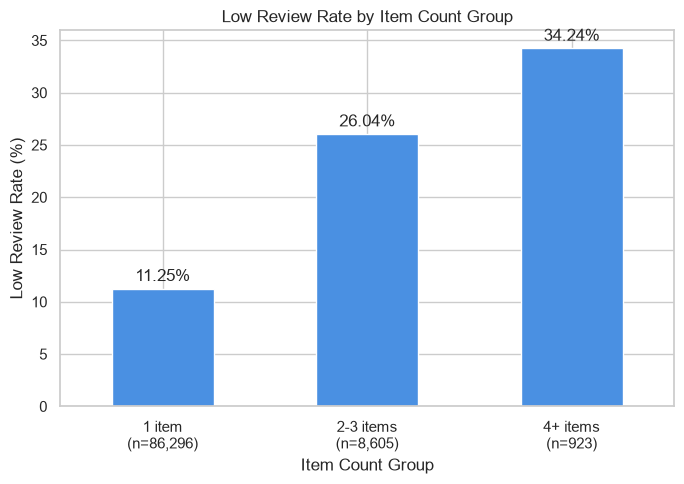

In [7]:
df["item_group"] = np.select(
    [df["item_count"] == 1, df["item_count"].between(2, 3)],
    ["1 item", "2-3 items"],
    default="4+ items",
)

summary = df.groupby("item_group")["low_review"].agg(["count", "mean"])
summary["low_review_rate"] = summary["mean"] * 100
summary = summary.reindex(["1 item", "2-3 items", "4+ items"])
print(summary.round(2))

ax = summary["low_review_rate"].plot(kind="bar", figsize=(7, 5), color="#4A90E2")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set_xticklabels([f"{name}\n(n={int(row['count']):,})" for name, row in summary.iterrows()], rotation=0)

plt.title("Low Review Rate by Item Count Group")
plt.xlabel("Item Count Group")
plt.ylabel("Low Review Rate (%)")
plt.tight_layout()
plt.show()

**Nhận xét:** tỷ lệ đánh giá thấp tăng theo số lượng sản phẩm: 11,25% với đơn 1 sản phẩm (86.296 đơn), 26,04% với đơn 2-3 sản phẩm (8.605 đơn) và 34,24% với đơn từ 4 sản phẩm (923 đơn). Chênh lệch giữa nhóm 1 sản phẩm và nhóm 2-3 sản phẩm là 14,79 điểm phần trăm, cho thấy số lượng sản phẩm có liên hệ với xác suất bị đánh giá thấp, dù nhóm 4+ sản phẩm có ít đơn hơn.

## 3.2.4. Spearman Correlation Heatmap

**Research Question:** How strongly are delivery delay, item count, and review score associated with each other?

Tính hệ số tương quan Spearman (phù hợp với dữ liệu không phân phối chuẩn và có nhiều giá trị ngoại lệ) giữa `delay_days`, `item_count` và `review_score`.

              delay_days  item_count  review_score
delay_days         1.000      -0.036        -0.176
item_count        -0.036       1.000        -0.108
review_score      -0.176      -0.108         1.000


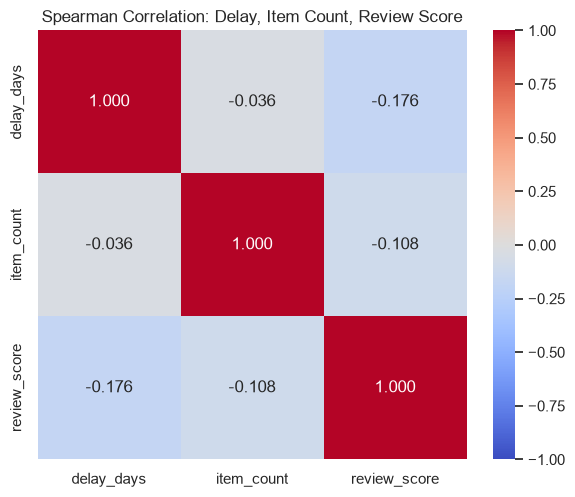

In [8]:
corr = df[["delay_days", "item_count", "review_score"]].corr(method="spearman")
print(corr.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation: Delay, Item Count, Review Score")
plt.tight_layout()
plt.show()

**Nhận xét:**
- `delay_days` và `review_score`: **-0,176** - tương quan âm yếu, đơn càng trễ thì điểm đánh giá càng có xu hướng thấp.
- `item_count` và `review_score`: **-0,108** - tương quan âm yếu, đơn nhiều sản phẩm có xu hướng bị đánh giá thấp hơn.
- `delay_days` và `item_count`: **-0,036** - gần như không tương quan, hai biến cung cấp thông tin khác nhau.

Cả hai biến đều tương quan yếu với điểm đánh giá, trong đó độ trễ có mức liên hệ cao hơn số lượng sản phẩm. Tương quan không chứng minh quan hệ nhân quả, và hệ số thấp không đủ để kết luận một biến không có giá trị dự đoán.

# 3.3. Feature Selection Insights

Tổng hợp kết quả của bốn biểu đồ để đưa ra quyết định ban đầu về hai biến đầu vào:

| Feature | Evidence from Analysis | Initial Decision |
|---|---|---|
| `delay_days` | Box Plot: trung vị độ trễ tăng từ -7 ngày (score 1) lên -13 ngày (score 5). Low Review Rate by Delivery Status: 62,37% (Late) so với 9,27% (On time / Early). Spearman: -0,176 với `review_score`. | Keep |
| `item_count` | Low Review Rate by Item Count Group: 11,25% (1 item), 26,04% (2-3 items), 34,24% (4+ items). Spearman: -0,108 với `review_score`. | Keep |

**Tổng kết:** cả hai biến đều có dấu hiệu liên quan đến khả năng bị đánh giá thấp. `delay_days` là biến có bằng chứng mạnh hơn ở cả ba góc nhìn (phân phối, tỷ lệ đánh giá thấp và tương quan), còn `item_count` cho thấy xu hướng tăng rõ ràng khi số sản phẩm trong đơn tăng. Tương quan giữa hai biến gần như bằng 0 (-0,036), nên chúng bổ sung thông tin cho nhau thay vì trùng lặp.

Quyết định **Keep** ở bước này chỉ mang tính định hướng: hệ số tương quan còn thấp, dữ liệu mất cân bằng (chỉ 12,8% đơn bị đánh giá thấp) và tương quan không đồng nghĩa với quan hệ nhân quả. Việc giữ hay loại biến cần được kiểm chứng thêm bằng mô hình Machine Learning ở giai đoạn sau.